# Analyze `optuna_search_kstest.py` results (augmented KS test)

Optuna TPE search with patience-based early stopping for `ammonyte.Series.kstest` (Bagniewski et al. 2021),
run on CARC on the noisier data (levels k1/k0p5/k0p25). Reads everything from `./noisier_results/`.
The ruptures counterpart lives in `../optuna_search/analyze_results.ipynb`.

- The KS search space is flat (`w_min`, `w_max`, `n_w`, `n_c`, `d_c`, `s_c`; `x_c` is never tuned, it is
  auto-computed per series), so there is no method x cost sweep. Views: best config, convergence, hyperparameter-vs-score.
- The held-out TEST split is scored once with `evaluate_test_kstest.py` (CARC, `evaluate_test_kstest.slurm`), which writes
  `best_test_raw.csv`. If missing, the test columns are skipped.
- KS detections are invariant to per-series standardization, so raw and standardized NGRIP should give identical results.

In [1]:
import json
import os
import sys
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from IPython.display import Image, display

import ammonyte as amt
from ammonyte.utils.metrics import evaluate_detection
from ammonyte.core.transitions import DeterministicTransitions

METHODS_DIR = os.path.abspath("..")   # Methods/ -- for analyze_noise_effect.py
sys.path.insert(0, METHODS_DIR)
from analyze_noise_effect import load_merged, summarize_all_splits, NOISIER_DATA_DIR
from optuna_search_kstest import _classify_detected_directions, TOLERANCE   # same direction classifier / tolerance as the search script

In [2]:
KS_RESULTS_DIR = "noisier_results"   # KS search on the NOISIER data (k1/k0p5/k0p25)

with open(os.path.join(KS_RESULTS_DIR, "best_params.json")) as f:
    ks_best_params = json.load(f)
KS_OBJECTIVE = ks_best_params.get("objective", "warming")

ks_trials_df = pd.read_csv(os.path.join(KS_RESULTS_DIR, "optuna_trials.csv"))
ks_conv_df = pd.read_csv(os.path.join(KS_RESULTS_DIR, "optuna_convergence.csv"))
ks_train_df = pd.read_csv(os.path.join(KS_RESULTS_DIR, "best_train_raw.csv"))
ks_val_df = pd.read_csv(os.path.join(KS_RESULTS_DIR, "best_validation_raw.csv"))

ks_test_csv = os.path.join(KS_RESULTS_DIR, "best_test_raw.csv")
ks_test_df = pd.read_csv(ks_test_csv) if os.path.exists(ks_test_csv) else None
if ks_test_df is None:
    print(f"{ks_test_csv} not found -- run `python evaluate_test_kstest.py --outdir results_ks` on CARC "
          "to score the winning KS config on held-out TEST (one-time, not run yet for the noisier data); test columns are skipped until then.")

print(f"objective optimized: f1_{KS_OBJECTIVE}")
ks_best_params

objective optimized: f1_warming


{'w_min': 0.3574867264895455,
 'w_max': 3.7762093217411987,
 'n_w': 9,
 'd_c': 0.5004824674960585,
 'n_c': 10,
 's_c': 0.8821196863629652,
 'x_c': None,
 'trial_number': 103,
 'objective': 'warming',
 'train_f1_all': 0.44917888770442366,
 'train_f1_warming': 0.4302263658517218,
 'train_f1_cooling': 0.4508056016519469,
 'train_mean_elapsed_s': 21.89927807976492,
 'run_metadata': {'wall_time_s': 10444.192135069054,
  'n_trials_this_run': 131,
  'n_trials_total': 131,
  'n_failed_total': 0,
  'patience': 50,
  'min_trials': 100,
  'min_delta': 0.01,
  'stopped_early': True,
  'stopped_at_trial': 130}}

## KS test: best configuration

The winning `(w_min, w_max, n_w, n_c, d_c, s_c)` and how the search ended (early stopping info comes
from `run_metadata`).

In [3]:
KS_PARAM_NAMES = ["w_min", "w_max", "n_w", "n_c", "d_c", "s_c", "x_c"]
ks_best_table = pd.Series({k: ks_best_params.get(k) for k in KS_PARAM_NAMES}, name="best value").to_frame()
ks_best_table.loc["x_c", "best value"] = "None (auto per series)" if ks_best_params.get("x_c") is None else ks_best_params["x_c"]
display(ks_best_table)

meta = ks_best_params.get("run_metadata", {})
print(f"winning trial:      #{ks_best_params['trial_number']}")
print(f"train f1_all / warming / cooling: {ks_best_params['train_f1_all']:.3f} / "
      f"{ks_best_params['train_f1_warming']:.3f} / {ks_best_params['train_f1_cooling']:.3f}")
print(f"mean time per series: {ks_best_params['train_mean_elapsed_s']:.1f} s")
print(f"trials run: {meta.get('n_trials_total')}  (failed: {meta.get('n_failed_total')})  "
      f"wall time: {meta.get('wall_time_s', float('nan'))/3600:.2f} h")
print(f"early stopping: patience={meta.get('patience')}, min_trials={meta.get('min_trials')}, "
      f"min_delta={meta.get('min_delta')}, stopped_early={meta.get('stopped_early')} "
      f"(at trial {meta.get('stopped_at_trial')})")

,best value
w_min,0.357487
w_max,3.776209
n_w,9.0
n_c,10.0
d_c,0.500482
s_c,0.88212
x_c,None (auto per series)


winning trial:      #103
train f1_all / warming / cooling: 0.449 / 0.430 / 0.451
mean time per series: 21.9 s
trials run: 131  (failed: 0)  wall time: 2.90 h
early stopping: patience=50, min_trials=100, min_delta=0.01, stopped_early=True (at trial 130)


## KS test: trial states and convergence

trials total: 131
state
COMPLETE    131
Name: count, dtype: int64
No trial recorded an error attribute.


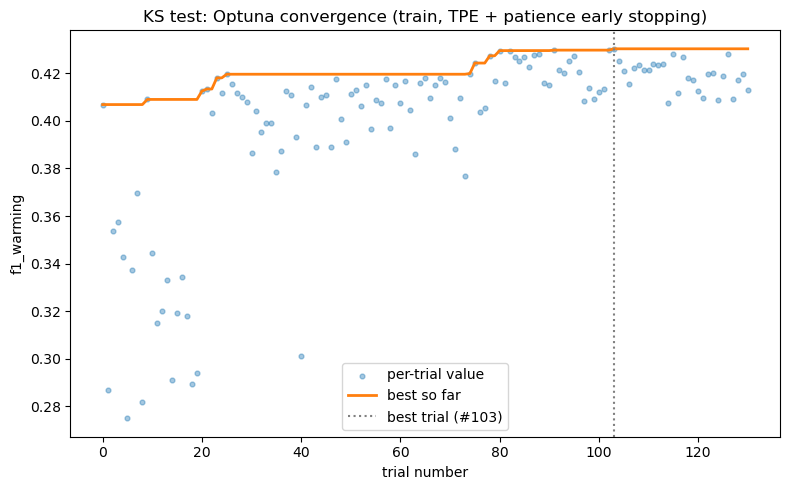

In [4]:
print(f"trials total: {len(ks_trials_df)}")
print(ks_trials_df['state'].value_counts())
if 'user_attrs_error' in ks_trials_df.columns:
    print(f"{ks_trials_df['user_attrs_error'].notna().sum()} trials recorded an error")
else:
    print("No trial recorded an error attribute.")

fig, ax = plt.subplots(figsize=(8, 5))
complete = ks_trials_df[ks_trials_df['state'] == 'COMPLETE'].sort_values('number')
ax.scatter(complete['number'], complete['value'], s=12, alpha=0.4, label='per-trial value')
ax.plot(ks_conv_df['number'], ks_conv_df['best_value_so_far'], color='C1', linewidth=2, label='best so far')
ax.axvline(ks_best_params['trial_number'], color='gray', linestyle=':', label=f"best trial (#{ks_best_params['trial_number']})")
ax.set_xlabel('trial number')
ax.set_ylabel(f"f1_{KS_OBJECTIVE}")
ax.set_title('KS test: Optuna convergence (train, TPE + patience early stopping)')
ax.legend()
fig.tight_layout()
plt.show()

## KS test: search space (train, every trial Optuna tried)

Each panel plots one hyperparameter against the trial's train `f1_warming`; color = trial number, so you can
see TPE concentrating on the good region over time. The dashed line marks the winning value.

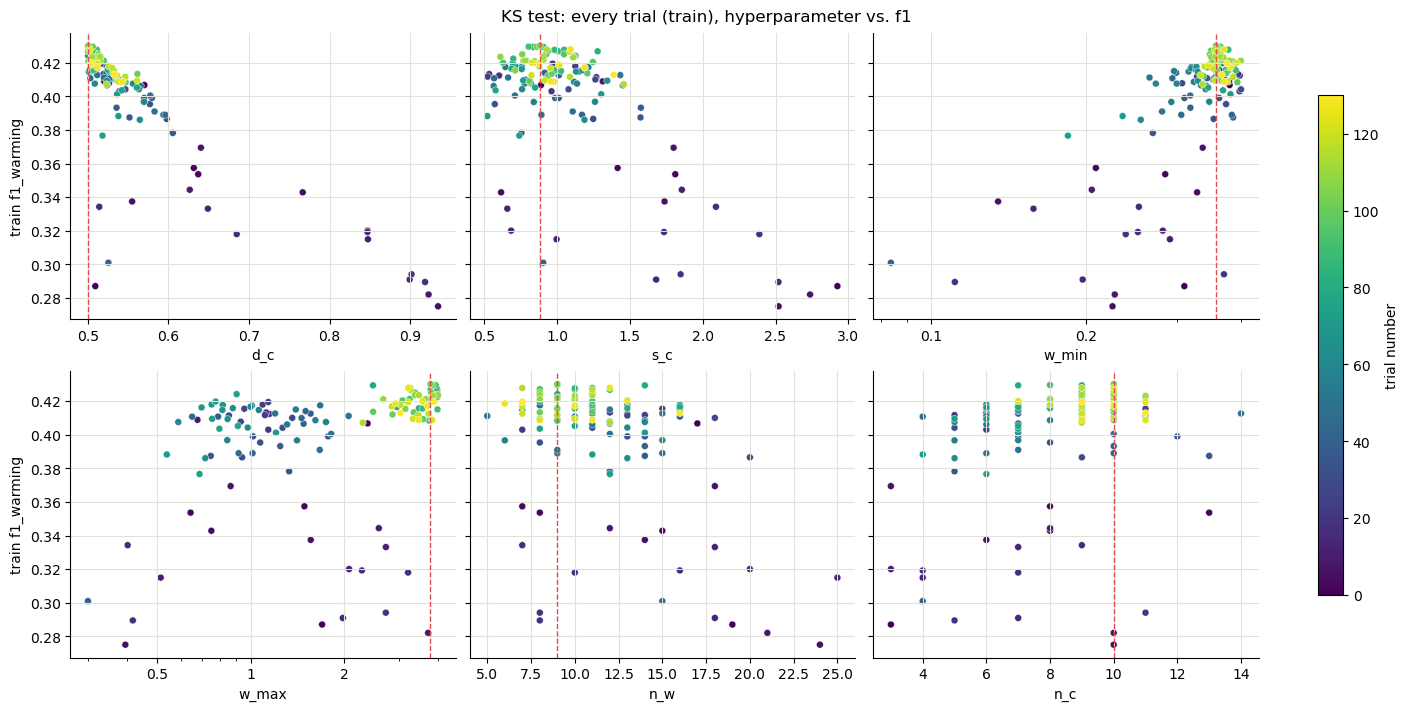

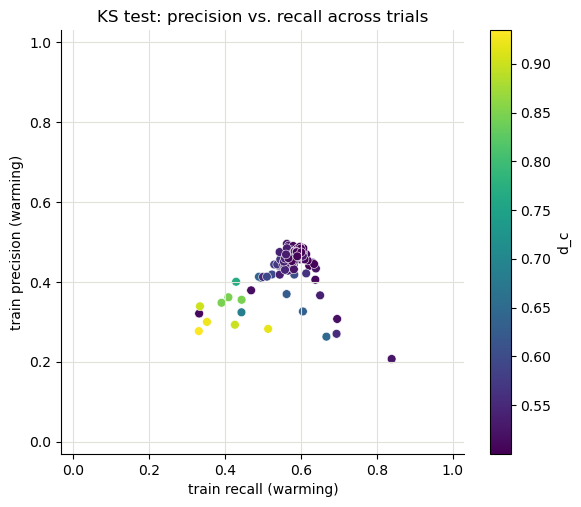

In [5]:
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

ks_params = [("params_d_c", "d_c"), ("params_s_c", "s_c"), ("params_w_min", "w_min"),
             ("params_w_max", "w_max"), ("params_n_w", "n_w"), ("params_n_c", "n_c")]
complete = ks_trials_df[ks_trials_df['state'] == 'COMPLETE']

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True, constrained_layout=True)
for ax, (col, name) in zip(axes.ravel(), ks_params):
    sc = ax.scatter(complete[col], complete['value'], c=complete['number'], cmap=SEQUENTIAL_BLUE if 'SEQUENTIAL_BLUE' in globals() else 'viridis',
                    s=25, edgecolor='white', linewidth=0.3)
    ax.axvline(ks_best_params[name], color='#e34948', linestyle='--', linewidth=1)
    ax.set_xlabel(name)
    if name in ("w_min", "w_max"):
        ax.set_xscale("log")
        ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))          # few, well-spaced labelled ticks
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))      # 0.4 instead of 4x10^-1
        ax.xaxis.set_minor_formatter(NullFormatter())                           # no overlapping minor labels
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel(f"train f1_{KS_OBJECTIVE}")
fig.colorbar(sc, ax=axes.ravel().tolist(), label="trial number", shrink=0.8)
fig.suptitle("KS test: every trial (train), hyperparameter vs. f1")
plt.show()

# precision vs recall (warming) across all trials, colored by d_c (the main sensitivity axis)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(complete[f'user_attrs_mean_recall_{KS_OBJECTIVE}'], complete[f'user_attrs_mean_precision_{KS_OBJECTIVE}'],
                c=complete['params_d_c'], cmap='viridis', s=40, edgecolor='white', linewidth=0.4)
ax.set_xlabel(f"train recall ({KS_OBJECTIVE})"); ax.set_ylabel(f"train precision ({KS_OBJECTIVE})")
ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
ax.grid(color="#e1e0d9", linewidth=0.8); ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(sc, label="d_c")
ax.set_title("KS test: precision vs. recall across trials")
plt.show()

## KS test: winning config, train vs. validation vs. test

Per-series breakdown for the single winning config, split by direction (`all` / `warming` / `cooling`).
Test is the one-time held-out evaluation of the frozen winning config.

In [6]:
ks_metric_cols = [c for c in ks_train_df.columns if c.startswith(('precision_', 'recall_', 'f1_'))]
ks_summary_data = {'train_mean': ks_train_df[ks_metric_cols].mean(), 'val_mean': ks_val_df[ks_metric_cols].mean()}
if ks_test_df is not None:
    ks_summary_data['test_mean'] = ks_test_df[ks_metric_cols].mean()
pd.DataFrame(ks_summary_data)

,train_mean,val_mean,test_mean
precision_all,0.500773,0.450419,0.451680
recall_all,0.631940,0.561447,0.637797
f1_all,0.449179,0.401812,0.464517
precision_warming,0.484401,0.364496,0.407717
recall_warming,0.606366,0.511852,0.595101
f1_warming,0.430226,0.376825,0.435286
precision_cooling,0.492780,0.454989,0.471501
recall_cooling,0.626228,0.579471,0.633963
f1_cooling,0.450806,0.408021,0.463488


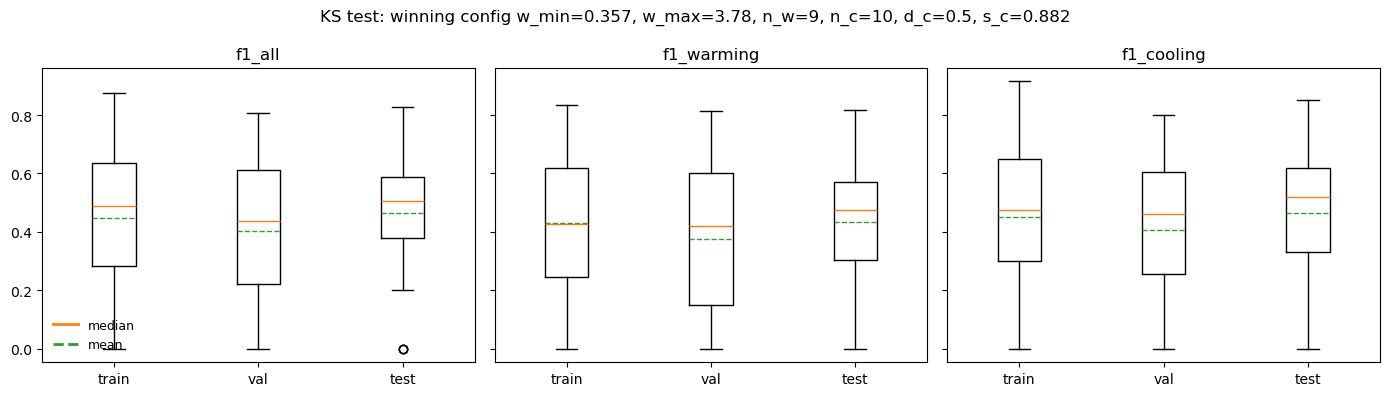

In [7]:
ks_splits = [('train', ks_train_df), ('val', ks_val_df)] + ([('test', ks_test_df)] if ks_test_df is not None else [])

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, label in zip(axes, ('all', 'warming', 'cooling')):
    ax.boxplot([df[f'f1_{label}'].dropna() for _, df in ks_splits],
               tick_labels=[name for name, _ in ks_splits], showmeans=True, meanline=True)
    ax.set_title(f'f1_{label}')
axes[0].legend(handles=[Line2D([0], [0], color='C1', linewidth=2, label='median'),
                        Line2D([0], [0], color='C2', linewidth=2, linestyle='--', label='mean')],
               loc='lower left', frameon=False, fontsize=9)
fig.suptitle("KS test: winning config " + ", ".join(f"{k}={ks_best_params[k]:.3g}" for k in ("w_min", "w_max", "n_w", "n_c", "d_c", "s_c")))
fig.tight_layout()
plt.show()

## KS test: noise-condition effect (winning config)

How noise **color** (white/pink/red) and **level** (SNR) change
detection performance, using `analyze_noise_effect.py` on the KS results (noisier split, levels k1/k0p5/k0p25). Heatmaps are saved into
`noisier_results/`, with train, validation and test side by side (test appears once
`best_test_raw.csv` is present).

In [8]:
KS_METRICS = [f'precision_{KS_OBJECTIVE}', f'recall_{KS_OBJECTIVE}', f'f1_{KS_OBJECTIVE}']

KS_MERGED_BY_SPLIT = {}
for split in ['train', 'validation', 'test']:
    merged = load_merged(KS_RESULTS_DIR, NOISIER_DATA_DIR, split)   # same noisier split as the KernelCPD section
    if merged is None:
        print(f"[{split}] best_{split}_raw.csv not found -- skipping")
    KS_MERGED_BY_SPLIT[split] = merged

In [9]:
from analyze_noise_effect import load_merged, summarize_all_splits, NOISIER_DATA_DIR
metric = KS_METRICS[0]   # precision_{KS_OBJECTIVE}
print(f"=== KS test: {metric} by noise condition -- train vs validation vs test (sorted by train mean) ===")
print(summarize_all_splits(KS_MERGED_BY_SPLIT, metric).to_string(float_format=lambda x: f"{x:.3f}"))

=== KS test: precision_warming by noise condition -- train vs validation vs test (sorted by train mean) ===
            train             validation              test            
             mean   std count       mean   std count  mean   std count
color level                                                           
white k1    0.868 0.083     6      0.809 0.074     3 0.804 0.081     4
      k0p5  0.676 0.308     7      0.500 0.433     3 0.600 0.304     3
      k0p25 0.667 0.516     6      0.000 0.000     5 0.000 0.000     3
red   k0p25 0.514 0.105     6      0.432 0.208     4 0.505 0.206     3
      k0p5  0.500 0.053     7      0.440 0.194     3 0.468 0.081     3
      k1    0.365 0.154     7      0.394 0.164     3 0.378 0.041     4
pink  k1    0.312 0.118     7      0.308 0.207     3 0.325 0.052     3
      k0p25 0.282 0.124     7      0.303 0.119     3 0.226 0.019     4
      k0p5  0.261 0.096     7      0.316 0.230     3 0.302 0.058     3


In [10]:
metric = KS_METRICS[1]   # recall_{KS_OBJECTIVE}
print(f"=== KS test: {metric} by noise condition -- train vs validation vs test (sorted by train mean) ===")
print(summarize_all_splits(KS_MERGED_BY_SPLIT, metric).to_string(float_format=lambda x: f"{x:.3f}"))

=== KS test: recall_warming by noise condition -- train vs validation vs test (sorted by train mean) ===
            train             validation              test            
             mean   std count       mean   std count  mean   std count
color level                                                           
red   k1    0.894 0.061     7      0.862 0.054     3 0.904 0.100     4
      k0p5  0.887 0.095     7      0.840 0.031     3 0.831 0.017     3
pink  k1    0.823 0.074     7      0.745 0.126     3 0.804 0.017     3
red   k0p25 0.725 0.086     6      0.588 0.049     4 0.668 0.102     3
pink  k0p5  0.701 0.097     7      0.544 0.161     3 0.734 0.117     3
white k1    0.700 0.114     6      0.663 0.139     3 0.700 0.068     4
pink  k0p25 0.541 0.075     7      0.618 0.042     3 0.501 0.030     4
white k0p5  0.097 0.012     7      0.063 0.057     3 0.108 0.061     3
      k0p25 0.038 0.036     6      0.000 0.000     5 0.000 0.000     3


In [11]:
metric = KS_METRICS[2]   # f1_{KS_OBJECTIVE}
print(f"=== KS test: {metric} by noise condition -- train vs validation vs test (sorted by train mean) ===")
print(summarize_all_splits(KS_MERGED_BY_SPLIT, metric).to_string(float_format=lambda x: f"{x:.3f}"))

=== KS test: f1_warming by noise condition -- train vs validation vs test (sorted by train mean) ===
            train             validation              test            
             mean   std count       mean   std count  mean   std count
color level                                                           
white k1    0.767 0.070     6      0.727 0.113     3 0.745 0.050     4
red   k0p5  0.636 0.042     7      0.562 0.184     3 0.595 0.063     3
      k0p25 0.593 0.058     6      0.479 0.133     4 0.569 0.170     3
      k1    0.499 0.145     7      0.530 0.164     3 0.532 0.053     4
pink  k1    0.439 0.113     7      0.418 0.227     3 0.461 0.053     3
      k0p5  0.366 0.083     7      0.384 0.237     3 0.427 0.077     3
      k0p25 0.355 0.121     7      0.398 0.110     3 0.311 0.018     4
white k0p5  0.166 0.023     7      0.111 0.100     3 0.182 0.102     3
      k0p25 0.071 0.067     6      0.000 0.000     5 0.000 0.000     3


### KS test: mean F1 vs SNR

Mean `f1_<objective>` at each noise level (k = SNR: sigma_noise = gap / k), one line per noise color plus the overall mean. Uses `KS_MERGED_BY_SPLIT` from above; set `SPLIT` to switch between train, validation and test.

=== KS test, test: mean f1_warming vs SNR ===
  snr  mean   sem  count
0.250 0.295 0.078     10
0.500 0.402 0.064      9
1.000 0.590 0.041     11


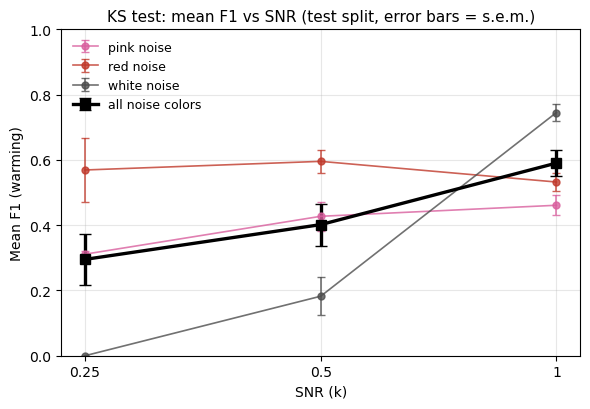

saved noisier_results/f1_vs_snr_test.png


In [12]:
# Mean F1 vs SNR (KS test, winning config). Level k = SNR: sigma_noise = gap / k, so k1 -> SNR 1, k0p5 -> 0.5, k0p25 -> 0.25.
SNR_OF_LEVEL = {"k1": 1.0, "k0p5": 0.5, "k0p25": 0.25}
SPLIT = "test"   # "train" / "validation" / "test"
metric = f"f1_{KS_OBJECTIVE}"
COLORS = {"white": "#4d4d4d", "pink": "#d95f9e", "red": "#c0392b"}

df = KS_MERGED_BY_SPLIT[SPLIT].assign(snr=lambda d: d["level"].map(SNR_OF_LEVEL))
by_color = df.groupby(["color", "snr"])[metric].agg(["mean", "sem"]).reset_index()
overall = df.groupby("snr")[metric].agg(["mean", "sem", "count"]).reset_index()
print(f"=== KS test, {SPLIT}: mean {metric} vs SNR ===")
print(overall.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

fig, ax = plt.subplots(figsize=(6, 4.2))
for color, g in by_color.groupby("color"):
    ax.errorbar(g["snr"], g["mean"], yerr=g["sem"], marker="o", ms=5, lw=1.2, capsize=3, alpha=0.8,
                color=COLORS.get(color), label=f"{color} noise")
ax.errorbar(overall["snr"], overall["mean"], yerr=overall["sem"], marker="s", ms=7, lw=2.4, capsize=4,
            color="black", label="all noise colors")
ax.set_xscale("log")
ticks = sorted(SNR_OF_LEVEL.values())
ax.set_xticks(ticks); ax.set_xticklabels([f"{v:g}" for v in ticks])
ax.minorticks_off()
ax.set_ylim(0, 1)
ax.set_xlabel("SNR (k)")
ax.set_ylabel(f"Mean F1 ({KS_OBJECTIVE})")
ax.set_title(f"KS test: mean F1 vs SNR ({SPLIT} split, error bars = s.e.m.)", fontsize=11)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
out = os.path.join(KS_RESULTS_DIR, f"f1_vs_snr_{SPLIT}.png")
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print(f"saved {out}")

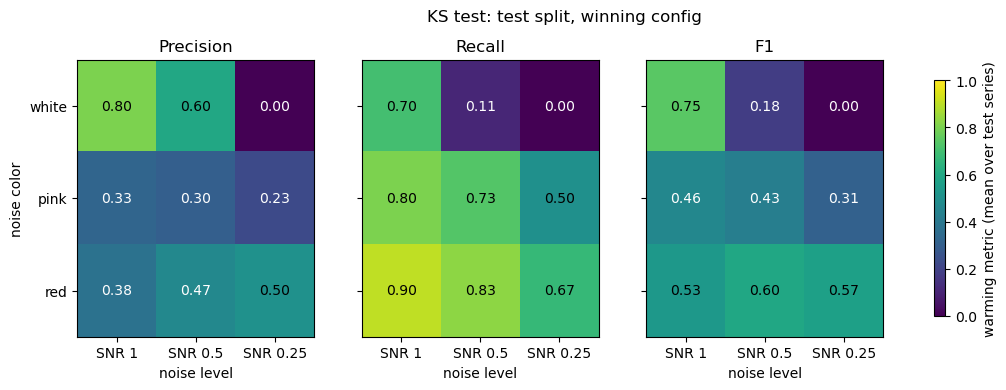

saved noisier_results/noise_heatmap_precision_recall_f1_test.png


In [13]:
# One figure for the report: KS test precision, recall and F1 side by side (test split, winning config), shared 0-1 colour scale.
_ORDER_LEVELS = ["k1", "k0p5", "k0p25"]            # clean -> noisy
_ORDER_COLORS = ["white", "pink", "red"]
_LEVEL_LABELS = {"k1": "SNR 1", "k0p5": "SNR 0.5", "k0p25": "SNR 0.25"}   # relative to the cleanest level
_titles = {"precision": "Precision", "recall": "Recall", "f1": "F1"}
_ks_test = KS_MERGED_BY_SPLIT["test"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, key in zip(axes, ["precision", "recall", "f1"]):
    pv = (_ks_test.pivot_table(index="color", columns="level", values=f"{key}_{KS_OBJECTIVE}", aggfunc="mean")
                  .reindex(index=_ORDER_COLORS, columns=_ORDER_LEVELS))
    im = ax.imshow(pv.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(_ORDER_LEVELS))); ax.set_xticklabels([_LEVEL_LABELS[l] for l in _ORDER_LEVELS])
    ax.set_yticks(range(len(_ORDER_COLORS))); ax.set_yticklabels(_ORDER_COLORS)
    ax.set_title(_titles[key]); ax.set_xlabel("noise level")
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.values[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.5 else "black")
axes[0].set_ylabel("noise color")
fig.suptitle("KS test: test split, winning config", y=1.02)
fig.colorbar(im, ax=axes.tolist(), shrink=0.85, label=f"{KS_OBJECTIVE} metric (mean over test series)")
out = os.path.join(KS_RESULTS_DIR, "noise_heatmap_precision_recall_f1_test.png")
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("saved", out)

   color  level  orig_seed  f1_warming
7  white  k0p25         18         0.0
8  white  k0p25         15         0.0
9  white  k0p25         26         0.0
series 7: true events 41 (warming 21) | detected 1 | classified warming 1
Detection Evaluation Metrics
Metrics calculated within tolerance = 0.5

Performance Scores:
+-----------+---------+
| Metric    |   Value |
+===========+=========+
| Precision |       0 |
+-----------+---------+
| Recall    |       0 |
+-----------+---------+
| F1 Score  |       0 |
+-----------+---------+

Detection Counts:
+-----------------+---------+
| Category        |   Count |
+=================+=========+
| True Positives  |       0 |
+-----------------+---------+
| False Positives |       1 |
+-----------------+---------+
| False Negatives |      21 |
+-----------------+---------+

Summary:
  Detected: 1 | Ground Truth: 21



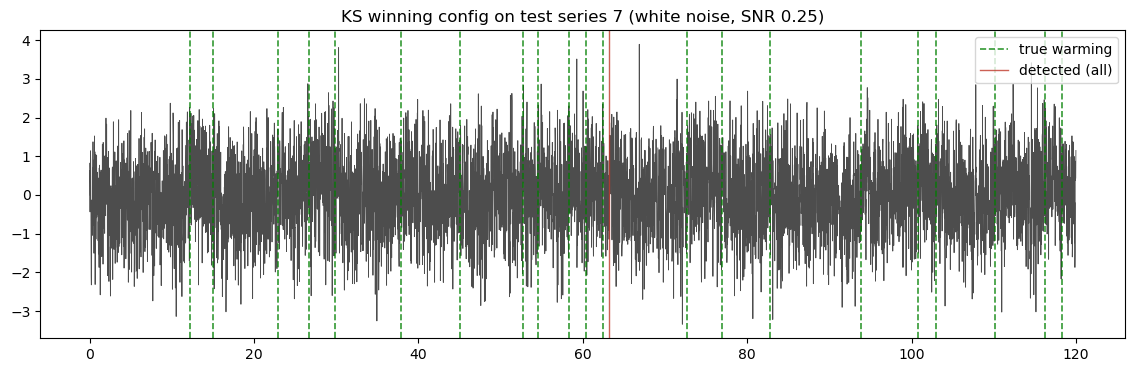

In [14]:
import sys
import ammonyte as amt
from ammonyte.utils.metrics import evaluate_detection
from analyze_noise_effect import load_merged, NOISIER_DATA_DIR

from optuna_search_kstest import load_split, _clean_times, _classify_detected_directions, TOLERANCE

KS_KWARGS = {k: ks_best_params[k] for k in ("w_min", "w_max", "n_w", "d_c", "n_c", "s_c")}

# --- pick a failed series: white noise, SNR 0.25, test split (F1 = 0 for all three) ---
split = "test"
merged = load_merged(KS_RESULTS_DIR, NOISIER_DATA_DIR, split)
failed = merged[(merged.color == "white") & (merged.level == "k0p25")]
print(failed[["color", "level", "orig_seed", "f1_warming"]])
i = int(failed.index[0])                      # row position = series index in the .npz

# --- same loading/standardization as the search script ---
time_arr, db, gt_times, gt_dirs, _ = load_split(os.path.join(NOISIER_DATA_DIR, f"{split}.npz"))
value, gt, gdir = db[i], np.asarray(gt_times[i]), np.asarray(gt_dirs[i])

# --- run the frozen winning KS config ---
series = amt.Series(time=time_arr, value=value, label="diag", verbose=False)
tr = series.kstest(w_min=KS_KWARGS["w_min"], w_max=KS_KWARGS["w_max"], n_w=int(KS_KWARGS["n_w"]),
                   d_c=KS_KWARGS["d_c"], n_c=int(KS_KWARGS["n_c"]), s_c=KS_KWARGS["s_c"], x_c=None)
det = _clean_times(tr.jump_times)
dirs = (_classify_detected_directions(value, time_arr, det, int(KS_KWARGS["n_c"]))
        if len(det) else np.array([]))
det_warm = det[dirs == "warming"] if len(det) else det
gt_warm = gt[gdir == "warming"]

print(f"series {i}: true events {len(gt)} (warming {len(gt_warm)}) | "
      f"detected {len(det)} | classified warming {len(det_warm)}")
print(evaluate_detection(detected=det_warm, ground_truth=gt_warm, tolerance=TOLERANCE))

# --- picture: detections vs. truth on this series ---
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(time_arr, value, color="0.3", lw=0.6)
for k, t in enumerate(gt_warm):
    ax.axvline(t, color="green", ls="--", lw=1.2, alpha=0.8, label="true warming" if k == 0 else None)
for k, t in enumerate(det):
    ax.axvline(t, color="#c0392b", lw=1, alpha=0.8, label="detected (all)" if k == 0 else None)
ax.set_title(f"KS winning config on test series {i} (white noise, SNR 0.25)")
ax.legend(loc="upper right"); plt.show()

## KS test applied to real NGRIP data

The frozen KS `best_params` (zero re-tuning) are applied to the NGRIP d18O record sliced to the DO-catalog window,
in forward time (time-reversed before detection, so warming = value goes up and the unmodified direction classifier applies).
Only **warming**-classified detections inside the labeled range are scored against the 25 real DO warming events (Rasmussen 2014).
`min_size` for the direction classifier is set to `n_c`, mirroring how the search script scored synthetic series.

NGRIP is run raw and standardized; KS is affine-invariant (with `x_c` auto), so both should be identical.
Each KS call is expensive (seconds to tens of seconds), so the scoring cell takes a minute or so.

In [15]:
# --- NGRIP in forward time, cut to the DO-catalog window (same construction as the ruptures notebook) ---
AMMONYTE_DATA_DIR = os.path.join(os.path.dirname(amt.__file__), "data")
ngrip_series = amt.Series.from_csv(os.path.join(AMMONYTE_DATA_DIR, "NGRIP.csv"))
do_df = pd.read_csv(os.path.join(AMMONYTE_DATA_DIR, "DO_onsets_Rasmussen2014.csv"), comment="#")   # 25 main GI onsets (Rasmussen 2014, Table 2)
do_gt_age = np.sort(do_df["main25_kyr_b2k"].dropna().values.astype(float))                          # kyr b2k

def to_forward_time(series):
    """age-ascending Series -> forward-time Series (time = -age ascending, values reversed)"""
    return amt.Series(time=-series.time[::-1], value=series.value[::-1],
                      time_name="time (forward)", time_unit="-kyr b2k",
                      value_name=series.value_name, value_unit=series.value_unit,
                      label=f"{series.label} (forward time)", verbose=False)

ngrip_win = to_forward_time(ngrip_series.slice([do_gt_age.min(), do_gt_age.max()]))
ngrip_standardized_series = ngrip_win.standardize()
do_gt_times = np.sort(-do_gt_age)

def to_age_axis(fwd_transitions, label):
    """forward-time detections -> DeterministicTransitions on the full NGRIP age axis (age = -time_fwd)"""
    ages = np.sort(-np.asarray(fwd_transitions.jump_times, float))
    return DeterministicTransitions(series=ngrip_series, jump_times=ages, jump_values=np.ones(len(ages)),
                                    method=fwd_transitions.method, method_args=fwd_transitions.method_args, label=label)

NGRIP_UNFILTERED = {}   # label -> in-range detections before direction filtering

print(f"NGRIP: {len(ngrip_series.time)} points; DO events: {len(do_gt_age)}, {do_gt_age.min():.2f}-{do_gt_age.max():.2f} kyr b2k")

KS_KWARGS = {k: ks_best_params[k] for k in ("w_min", "w_max", "n_w", "d_c", "n_c", "s_c")}

def score_ngrip_ks(series, gt_times, tolerance, label, w_min, w_max, n_w, d_c, n_c, s_c):
    transitions = series.kstest(w_min=w_min, w_max=w_max, n_w=int(n_w), d_c=d_c, n_c=int(n_c), s_c=s_c, x_c=None)
    detected_all = np.unique(np.asarray(transitions.jump_times, dtype=float))

    # scoring rules: only the labeled range, only warming-classified
    in_range = (detected_all >= gt_times.min()) & (detected_all <= gt_times.max())
    detected = detected_all[in_range]
    # forward-time NGRIP, same as the synthetic data: original classifier, no sign flip.
    det_directions = _classify_detected_directions(series.value, series.time, detected, int(n_c))
    detected_warming = detected[det_directions == "warming"]
    NGRIP_UNFILTERED[label] = detected
    print(f"--- {label}: {len(detected_all)} changepoints detected, "
          f"{(~in_range).sum()} outside the labeled range (dropped), {len(detected)} in range, "
          f"{len(detected_warming)} classified warming (scored below) ---")

    metrics = evaluate_detection(detected=detected_warming, ground_truth=gt_times, tolerance=tolerance)
    print(metrics)

    warming_transitions = DeterministicTransitions(
        series=series, jump_times=detected_warming, jump_values=np.ones(len(detected_warming)),
        method=transitions.method, method_args=transitions.method_args,
        label=f"{label} (warming only)")
    return warming_transitions, detected_warming, metrics

ks_ngrip_raw_tr, ks_ngrip_raw_det, ks_ngrip_raw_metrics = score_ngrip_ks(
    ngrip_win, do_gt_times, TOLERANCE, "KS, raw NGRIP scale", **KS_KWARGS)
print()
ks_ngrip_std_tr, ks_ngrip_std_det, ks_ngrip_std_metrics = score_ngrip_ks(
    ngrip_standardized_series, do_gt_times, TOLERANCE, "KS, standardized NGRIP", **KS_KWARGS)

print(f"\nf1_warming: raw={ks_ngrip_raw_metrics.f1_score:.3f}  standardized={ks_ngrip_std_metrics.f1_score:.3f}")
print("identical detections (expected, KS is affine-invariant):", np.allclose(ks_ngrip_raw_det, ks_ngrip_std_det) if len(ks_ngrip_raw_det) == len(ks_ngrip_std_det) else False)

Time axis values sorted in ascending order
Time axis values sorted in ascending order
NGRIP: 6112 points; DO events: 25, 14.69-115.37 kyr b2k
--- KS, raw NGRIP scale: 63 changepoints detected, 0 outside the labeled range (dropped), 63 in range, 27 classified warming (scored below) ---
Detection Evaluation Metrics
Metrics calculated within tolerance = 0.5

Performance Scores:
+-----------+---------+
| Metric    |   Value |
+===========+=========+
| Precision |  0.8148 |
+-----------+---------+
| Recall    |  0.88   |
+-----------+---------+
| F1 Score  |  0.8462 |
+-----------+---------+

Detection Counts:
+-----------------+---------+
| Category        |   Count |
+=================+=========+
| True Positives  |      22 |
+-----------------+---------+
| False Positives |       5 |
+-----------------+---------+
| False Negatives |       3 |
+-----------------+---------+

Summary:
  Detected: 27 | Ground Truth: 25


--- KS, standardized NGRIP: 63 changepoints detected, 0 outside the lab

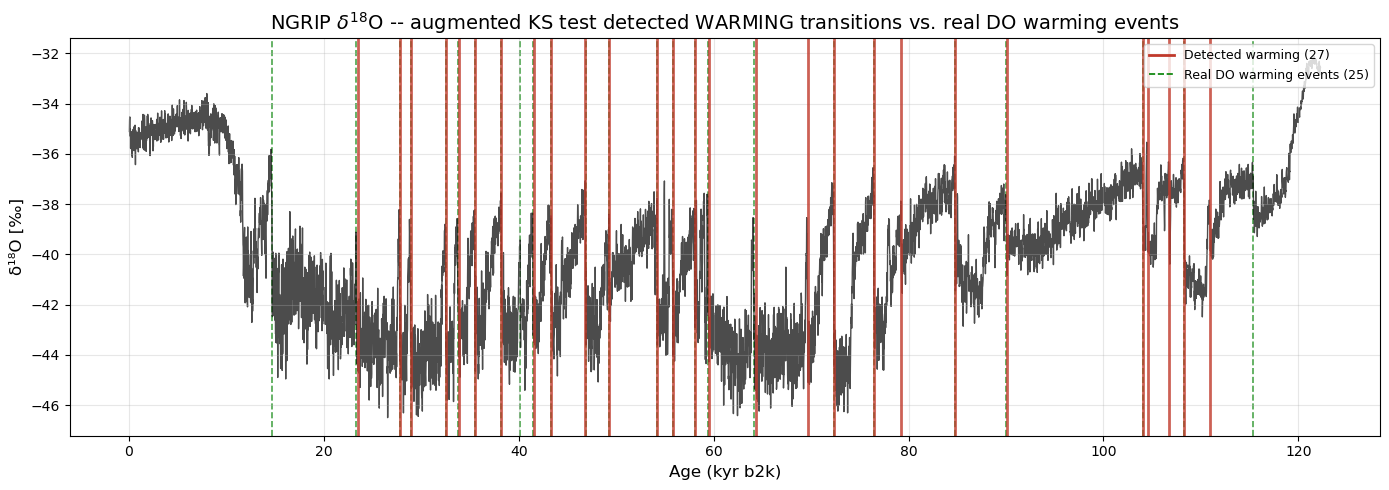

In [16]:
# same idea as the KernelCPD figure: computed in forward time, drawn on the original NGRIP age axis
ks_age_transitions = to_age_axis(ks_ngrip_std_tr, "KS warming (age axis)")
fig, ax = ks_age_transitions.plot(
    figsize=(14, 5), show_transitions="all", transition_color="#c0392b",
    legend_labels=[f"Detected warming ({len(ks_ngrip_std_det)})"],
    title="NGRIP $\\delta^{18}$O -- augmented KS test detected WARMING transitions vs. real DO warming events",
)
for t in do_gt_age:
    ax.axvline(t, color="green", linestyle="--", linewidth=1.2, alpha=0.7, zorder=0)
ax.plot([], [], color="green", linestyle="--", linewidth=1.2, label=f"Real DO warming events ({len(do_gt_age)})")
ax.set_xlabel("Age (kyr b2k)")
ax.legend(loc="upper right", fontsize=9)
plt.show()

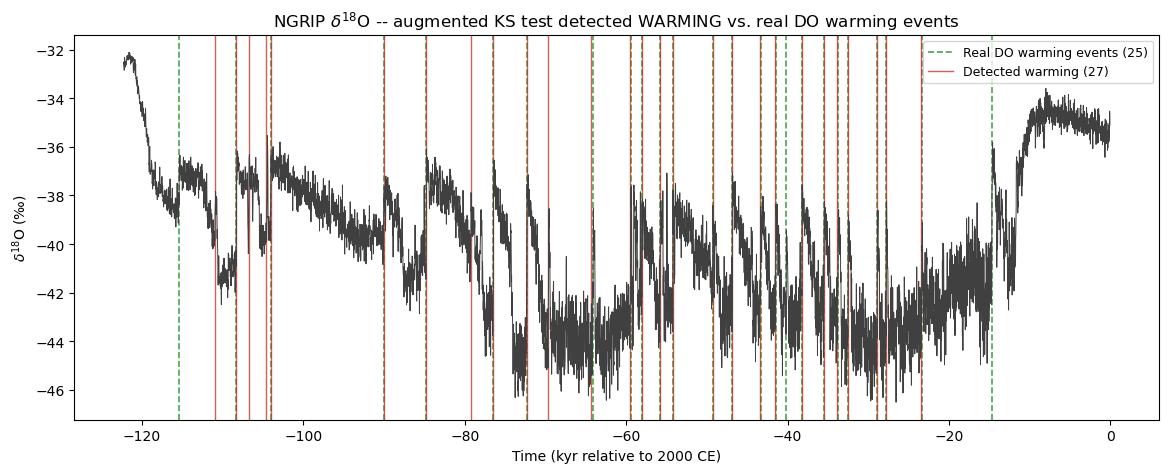

In [17]:
# Same KS detections, drawn in forward time (x = time relative to 2000 CE, i.e. -age: past on the left, present on the right),
# with the NGRIP record reversed to match -- the orientation the detector and direction classifier worked in.
# Nothing is recomputed: detections and DO onsets are already in forward time; only the raw record is flipped for display.
fwd_time = -ngrip_series.time[::-1]
fwd_value = ngrip_series.value[::-1]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(fwd_time, fwd_value, color="0.25", lw=0.7)
for k, t in enumerate(do_gt_times):
    ax.axvline(t, color="green", ls="--", lw=1.2, alpha=0.7, zorder=0, label=f"Real DO warming events ({len(do_gt_times)})" if k == 0 else None)
for k, t in enumerate(ks_ngrip_std_det):
    ax.axvline(t, color="#c0392b", lw=1.0, alpha=0.8, zorder=1, label=f"Detected warming ({len(ks_ngrip_std_det)})" if k == 0 else None)
ax.set_xlabel("Time (kyr relative to 2000 CE)")
ax.set_ylabel(r"$\delta^{18}$O (‰)")
ax.set_title("NGRIP $\\delta^{18}$O -- augmented KS test detected WARMING vs. real DO warming events")
ax.legend(loc="upper right", fontsize=9)
plt.show()

In [18]:
# Side-by-side: KS synthetic splits vs. real NGRIP.
def _means(df):
    return [df['precision_warming'].mean(), df['recall_warming'].mean(), df['f1_warming'].mean()]

ks_ngrip_comparison = pd.DataFrame({
    'KS train': _means(ks_train_df),
    'KS validation': _means(ks_val_df),
    'KS test': _means(ks_test_df) if ks_test_df is not None else [np.nan] * 3,
    'KS NGRIP (raw)': [ks_ngrip_raw_metrics.precision, ks_ngrip_raw_metrics.recall, ks_ngrip_raw_metrics.f1_score],
    'KS NGRIP (standardized)': [ks_ngrip_std_metrics.precision, ks_ngrip_std_metrics.recall, ks_ngrip_std_metrics.f1_score],
}, index=['precision_warming', 'recall_warming', 'f1_warming'])
ks_ngrip_comparison = ks_ngrip_comparison.dropna(axis=1, how='all')   # drops the KS test column while test is not scored
ks_ngrip_comparison

,KS train,KS validation,KS test,KS NGRIP (raw),KS NGRIP (standardized)
precision_warming,0.484401,0.364496,0.407717,0.814815,0.814815
recall_warming,0.606366,0.511852,0.595101,0.880000,0.880000
f1_warming,0.430226,0.376825,0.435286,0.846154,0.846154
